# X-Wines: Predicting Wine Ratings

**Research question:** How much do historical ratings, wine attributes, and rating context contribute to predicting a later wine rating?

Historical ratings, wine attributes, and rating context are evaluated on a shared chronological split, with separate checks for unseen wines and recommendation ranking.

[Prediction and study design](#prediction) · [Related research](#research) · [Data and exploration](#data) · [Models and implementation](#models) · [Evaluation and interpretation](#evaluation) · [Conclusions](#conclusions) · [Reproduction](#reproduction)

In [1]:
#@title Load report data
import base64, hashlib, io, json, zlib
_ARCHIVE = '...'
SNAPSHOT = json.loads(zlib.decompress(base64.b64decode(_ARCHIVE)))
for _name, _text in SNAPSHOT["reports"].items():
    if hashlib.sha256(_text.encode()).hexdigest() != SNAPSHOT["hashes"][_name]:
        raise ValueError(f"Changed embedded report: {_name}")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
WINE, GRAY = '#713e50', '#7a858c'
def report(name, **kwargs):
    return pd.read_csv(io.StringIO(SNAPSHOT['reports'][name]), **kwargs)
def figure(name):
    display(Image(data=base64.b64decode(SNAPSHOT['images'][name])))
def show_code(name):
    source = SNAPSHOT['sources'][name]
    url = ('https://github.com/AviGon/Wine_Recommendation_System/blob/'
           + SNAPSHOT['source_commit'] + '/' + source['path'] + '#L' + str(source['line']))
    display(Markdown(f"[{source['path']} — {source['symbol']}]({url})"))
    display(Code(source['code'], language='python'))
def finish(fig, caption):
    plt.show()
    display(Markdown('*'+caption+'*'))
print('Data revision:', SNAPSHOT['source_commit'][:7])

Data revision: 9bba3f2


<a id="prediction"></a>
## Prediction objective and study design

Given user $u$, wine $i$, and declared query context, predict the continuous rating $r_{ui}\in[1,5]$. User and wine identity, catalogue attributes, rating date, and rated vintage are possible inputs. **Rating date and vintage must be known for context-aware predictions.** We predict ratings conditional on an observed rating event, not purchases, sales, or satisfaction across all unobserved pairs.

The primary question is future-rating prediction. A global chronological split uses 120,000 training, 15,000 validation, and 15,000 test events. Timestamp ties stay together. Training fits every vocabulary, imputer, aggregate, and parameter; validation selects settings; test evaluates the selected configurations. Predictions are clipped to [1,5], without half-star rounding.

**RMSE** is primary because large rating errors receive a larger penalty. **MAE** gives a more direct typical absolute error in stars. Neither measures list quality, so ranking is a separate, secondary experiment. Global/user/item means, additive user–wine biases, and a linear model with the same features provide comparison points before attributing gains to model complexity.

In [3]:
coverage = report('split_coverage.csv')
primary = coverage[coverage.protocol.eq('chronological')].copy()
display(primary[['partition', 'n', 'users', 'wines', 'start', 'end', 'warm_both', 'new_user_only']])

,partition,n,users,wines,start,end,warm_both,new_user_only
0,train,120000,10357,1000,2012-04-19 20:46:00,2020-08-25 01:57:25,1.000000,0.000000
1,validation,15000,6081,838,2020-08-25 02:29:49,2021-04-20 23:20:48,0.946467,0.053133
2,test,15000,5788,822,2021-04-20 23:30:05,2021-12-31 23:58:52,0.933533,0.065400


**Sensitivity protocols.** Random splitting keeps repeated user–wine pairs together; it asks a different interpolation question. The disjoint-wine protocol puts complete wines in separate partitions and tests prediction without an item's rating history. It simulates missing history, not actual launch dates. The same saved membership hashes underpin the model notebooks. Scores across protocols do not share identical test distributions.

<a id="research"></a>
## Related research and model choices

**Dataset origin.** [de Azambuja, Morais and Filipe (2023), X-Wines](https://doi.org/10.3390/bdcc7010020) introduce an open wine-rating dataset assembled from web sources in 2022. Their examples include neighbourhood recommendation and comparisons of recommender algorithms. We use the smaller Slim edition to compare identity, static attributes, and context under fixed partitions; our protocols and scores are not a direct replication of their published experiments.

**Neighbourhood recommendation.** [Sarwar et al. (2001), Item-Based Collaborative Filtering Recommendation Algorithms](https://files.grouplens.org/papers/www10_sarwar.pdf) motivate prediction from item similarities. Our implementation compares Jaccard, cosine and Pearson similarities and shrinks neighbour corrections toward an additive bias prediction. The resulting gain is small on this sample, so similarity alone does not explain the larger gains of context-aware models.

**Latent factors.** [Koren, Bell and Volinsky (2009), Matrix Factorization Techniques for Recommender Systems](https://doi.org/10.1109/MC.2009.263) describe bias terms, regularized latent factors and extensions of collaborative filtering. Those ideas motivate our bias, ALS, SVD and SVD++ comparisons. Their success in other rating domains is motivation rather than evidence of a gain on Slim; our tuned factors do not clearly outperform the additive reference.

**Sparse feature interactions.** [Rendle (2010), Factorization Machines](https://www.ismll.uni-hildesheim.de/pub/pdfs/Rendle2010FM.pdf) describes factorized interactions among general sparse features, unifying several factorization models. We borrow the second-order prediction equation and efficient interaction calculation. Here, a matched linear model has almost the same test error as the FM, so additional interactions do not show a material point-estimate gain.

**Temporal drift.** [Koren (2010), Collaborative Filtering with Temporal Dynamics](https://courses.ischool.berkeley.edu/i290-dm/s11/SECURE/p89-koren.pdf) models changing rating behaviour on Netflix. Our simpler year/month features are motivated by that concern, but are not timeSVD++. Their validation improvement agrees with the importance of drift; different datasets and protocols prevent a numerical comparison with Netflix results.

**Similar review data.** [McAuley and Leskovec (2013), Hidden Factors and Hidden Topics](https://cseweb.ucsd.edu/~jmcauley/pdfs/recsys13.pdf) study rating prediction with review text, including wine/CellarTracker data. Their text-informed factors can help sparse cases. These X-Wines CSVs do not expose the corresponding review text, so we examine structured attributes instead and cannot claim to reproduce the text-based method.

**Strong references.** [Rendle, Zhang and Koren (2019), On the Difficulty of Evaluating Baselines](https://arxiv.org/abs/1905.01395) show how careful baseline tuning can change apparent model advantages. This motivates comparing FM against a linear model with identical features and tuned regularization. Their results do not imply that simple models always win; our conclusion is limited to these experiments.

<a id="data"></a>
## Dataset, collection and preprocessing

The authors collected and validated ratings from 2012–2021. Their Full edition reports 100,646 wines and about 21 million ratings; those are published counts, not a Full-edition experiment here. Slim is the measured study sample. User identifiers are anonymized; production country and region are wine attributes, not consumer locations. Prices and purchase/exposure records are unavailable.

The upstream `Test` edition is a small example dataset, distinct from our held-out test partitions. Catalogue attributes are a retrospective 2022 snapshot. A chronological split cannot establish that every attribute was available at each historical rating time.

In [4]:
summary = report('dataset_summary.csv', index_col=0)
display(summary.loc[['ratings', 'users', 'catalog_wines', 'countries', 'wine_types',
                     'date_min', 'date_max', 'sparsity', 'repeated_user_wine_rows']])

,Test edition,Slim edition
ratings,1000,150000
users,636,10561
catalog_wines,100,1007
countries,17,31
wine_types,6,6
date_min,2012-07-19 12:40:37,2012-04-19 20:46:00
date_max,2021-12-31 12:17:41,2021-12-31 23:58:52
sparsity,0.9842767295597484,0.9858955308296897
repeated_user_wine_rows,0,0


### Ratings, activity and sampling

Rating mass is concentrated above the midpoint and activity is uneven across users and wines. Review frequency describes the sampled rating process; it is not a direct measure of demand. Sparse histories motivate regularization and explicit fallbacks for unseen IDs.

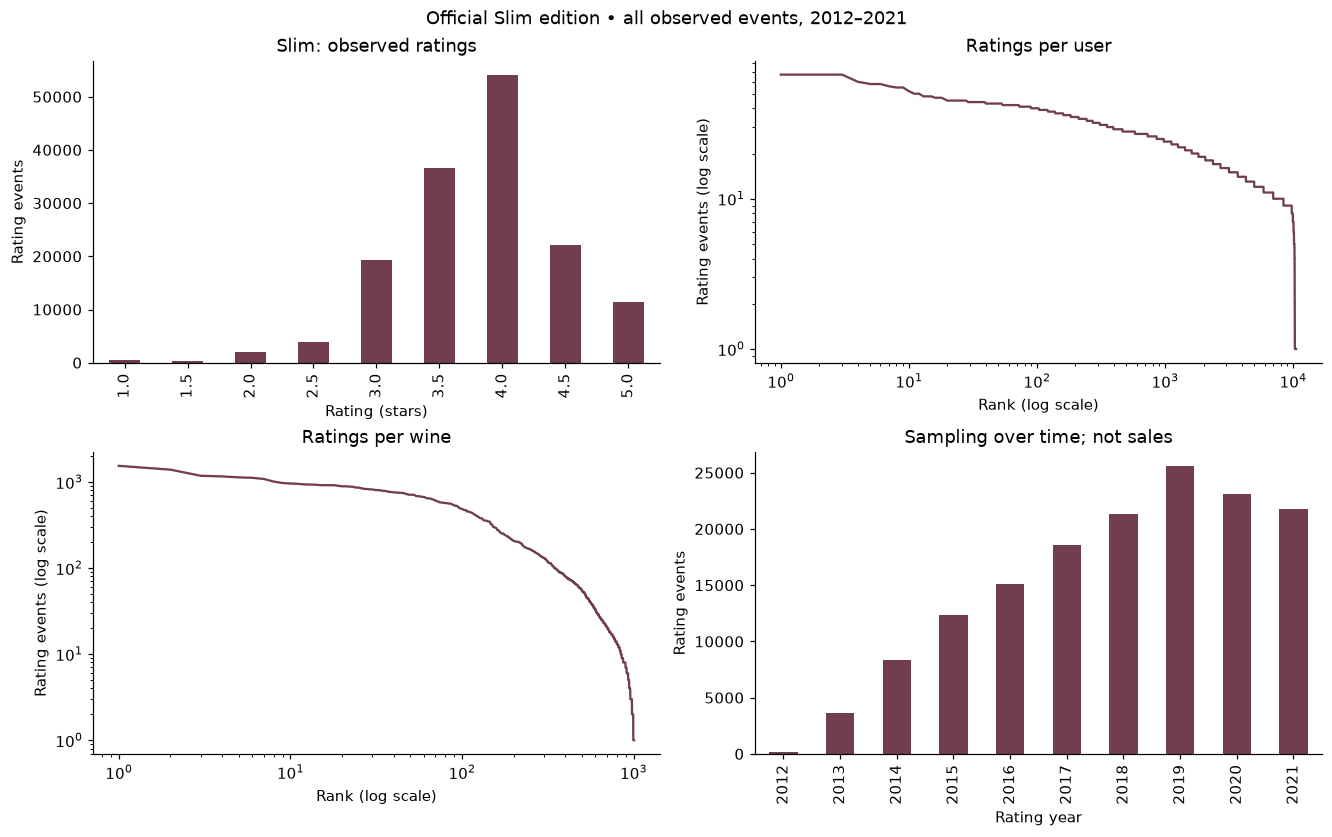

In [5]:
figure('rating_activity')

### Wine attributes and observed preferences

Review exposure and catalogue composition differ: a country can contain many wines yet account for fewer reviews. Type-level means below show both event weighting and equal weight per wine; neither removes selection bias. Interpretations should concern associations, not intrinsic country or grape quality.

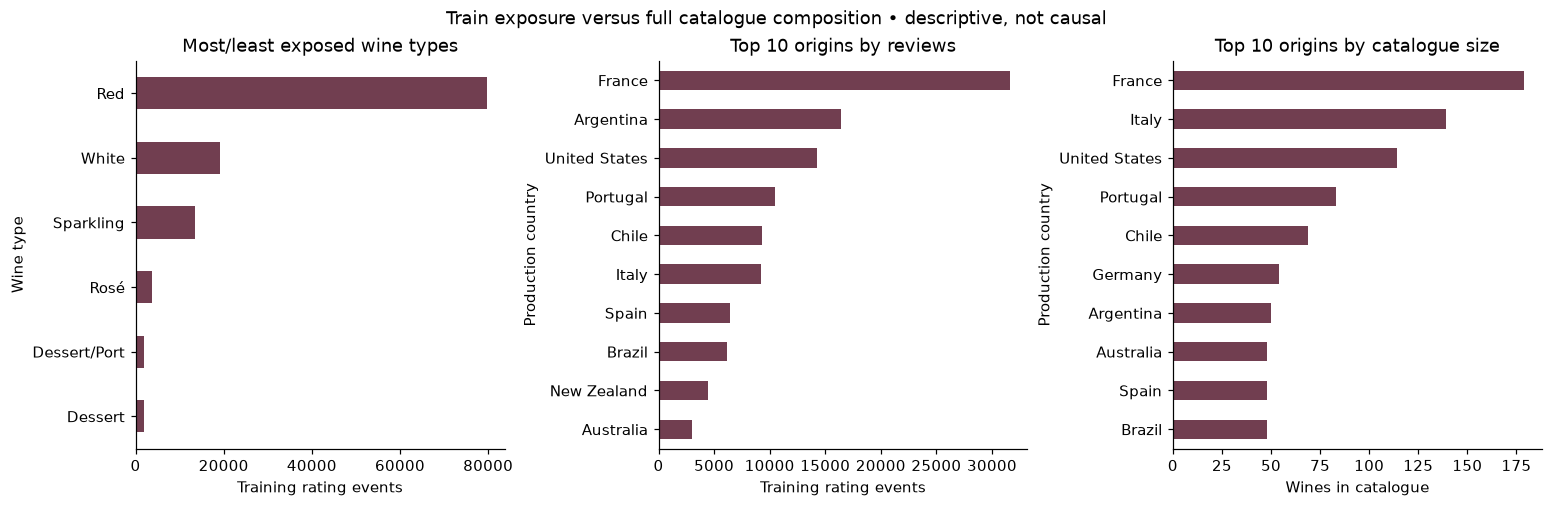

,Type,ratings,users,wines,mean_rating,equal_wine_mean
0,Red,79726,10171,506,3.828444,3.683592
1,White,19186,7348,230,3.641822,3.566809
2,Sparkling,13472,5938,98,3.789230,3.695046
3,Rosé,3711,2796,83,3.399623,3.368821
4,Dessert/Port,2000,1570,25,3.818750,3.869493
5,Dessert,1905,1623,58,4.054068,3.854475


eligible_users    4630.000000
mean_delta           0.160191
ci_low               0.148260
ci_high              0.172679
Name: Within-user Red minus White rating, dtype: float64

In [6]:
figure('categories_origins')
display(report('train_type_summary.csv'))
effects = json.loads(SNAPSHOT['reports']['eda_effects.json'])
display(pd.Series(effects['red_white'], name='Within-user Red minus White rating'))

The Red–White comparison averages within-user differences among users with at least two ratings of each type. It does not isolate a causal type effect. The later split-half analysis asks a different question: whether residual preferences repeat after accounting for user/wine biases. A positive mean type difference can coexist with weak residual preference stability.

### Feature representation and data quality

IDs and origin/type fields are categorical. Grape blends use fractional multi-hot weights of 1/k. ABV is scaled and imputed using unique training wines. Non-vintage or invalid ages use a training median and a missing indicator. Rating month uses sine/cosine; rating year and vintage age have declared scales. Entire catalogue vintage lists are excluded because they can contain later availability information.

Every metadata join preserves rating rows or raises an error. Unknown categorical levels contribute no learned coefficient; known bias/content terms provide fallbacks. Body/Acidity are partly review-derived and appear only in a caveated sensitivity experiment. Prices are never imputed from unrelated sources.

In [7]:
quality = report('metadata_quality.csv', index_col=0)
display(quality[quality['missing'].gt(0)])
show_code('encoder')

,missing,unique_values
Website,107,689.0


[src/fm.py — FMEncoder.fit](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/src/fm.py#L113)

def fit(self, frame):
    wines = frame.drop_duplicates('WineID')
    abv = pd.to_numeric(wines.ABV, errors='coerce') if 'ABV' in frame else pd.Series(dtype=float)
    self.abv_median = float(abv.median()) if abv.notna().any() else 0.
    self.abv_sd = float(abv.std()) if abv.notna().sum() > 1 and abv.std() > 0 else 1.
    age = _age(frame) if {'Date', 'Vintage'} <= set(frame) else np.array([np.nan])
    self.age_median = float(np.nanmedian(age)) if np.isfinite(age).any() else 0.
    names, fields = [], []
    for field, _, col, _ in self._entries(frame):
        new = pd.unique(col)
        names.extend(new); fields.extend([field] * len(new))
    order = pd.Index(names)
    keep = ~order.duplicated()
    self.columns = order[keep]
    self.column_field = np.array(fields, dtype=object)[keep]
    self.index = pd.Series(np.arange(len(self.columns)), index=self.columns)
    return self

<a id="models"></a>
## Models, objectives and implementation

The progression tests whether complexity contributes beyond strong references:

- **Additive bias:** $\hat r_{ui}=\mu+b_u+b_i$, squared loss with separate user/item L2 penalties; alternating closed-form updates.
- **Item-based CF:** bias prediction plus a damped weighted mean of neighbours' training residuals. Similarity choice, neighbourhood size and damping are selected on validation.
- **Matrix factorization:** $\mu+b_u+b_i+p_u^Tq_i$, with regularized squared loss. Our solver uses alternating ridge solves; Surprise SVD uses SGD; SVD++ includes an implicit-feedback component.
- **Linear content/context:** a sparse encoded feature vector with L2 regularization; a matched linear reference has the same inputs as the FM.
- **Factorization machine:** $w_0+\sum_jw_jx_j+\sum_{j<l}\langle v_j,v_l\rangle x_jx_l$. Full-batch L-BFGS optimizes squared error with separate linear/factor penalties. At k=0 it reduces to a linear model.

Regression matches the rating target and loss. Classification accuracy is not the same objective; a classification approach would need an explicitly ordered loss or conversion to a comparable expected rating. Pairwise implicit-feedback objectives answer the separate ranking question.

In [8]:
show_code('bias')
show_code('neighbours')

[src/cf.py — BiasBaseline.fit](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/src/cf.py#L50)

def fit(self, train):
    users = train.UserID.to_numpy(); items = train.WineID.to_numpy()
    r = train.Rating.to_numpy(dtype=float)
    self.mu = float(r.mean())
    self.user_ids, u = np.unique(users, return_inverse=True)
    self.item_ids, i = np.unique(items, return_inverse=True)
    n_u = np.bincount(u, minlength=len(self.user_ids))
    n_i = np.bincount(i, minlength=len(self.item_ids))
    bu = np.zeros(len(self.user_ids)); bi = np.zeros(len(self.item_ids))
    for _ in range(self.n_iter):
        bi = np.bincount(i, r - self.mu - bu[u], len(bi)) / (self.reg_item + n_i)
        bu = np.bincount(u, r - self.mu - bi[i], len(bu)) / (self.reg_user + n_u)
    self.bu = pd.Series(bu, index=self.user_ids)
    self.bi = pd.Series(bi, index=self.item_ids)
    self.user_count = pd.Series(n_u, index=self.user_ids)
    self.item_count = pd.Series(n_i, index=self.item_ids)
    return self

[src/cf.py — ItemCF.raw](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/src/cf.py#L148)

def raw(self, frame):
    base = self.baseline.raw(frame)
    items = frame.WineID.map(self.item_index).to_numpy()
    out = base.copy()
    self.neighbour_rows = 0
    for row, (user, item) in enumerate(zip(frame.UserID.to_numpy(), items)):
        if np.isnan(item) or user not in self.history:
            continue
        js, res = self.history[user]
        s = self.sim[int(item), js]
        keep = s > 0
        if not keep.any():
            continue
        s, res = s[keep], res[keep]
        if len(s) > self.k:
            top = np.argpartition(-s, self.k)[:self.k]
            s, res = s[top], res[top]
        out[row] += s @ res / (s.sum() + self.damping)
        self.neighbour_rows += 1
    return out

### Sparse latent factors and feature interactions

ALS solves one regularized least-squares block at a time. The FM calculates all second-order interactions using sparse matrix products instead of enumerating every pair. Both require regularization: adding dimensions can reduce training error without improving validation. User/item factors can collapse toward the additive model when penalized strongly.

In [9]:
show_code('als')
show_code('fm')

[src/cf.py — ALSMF._solve](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/src/cf.py#L192)

@staticmethod
def _solve(groups, other_bias, other_vec, reg, reg_bias):
    """For each row group: ridge of target - other_bias on [1, other_vec]."""
    k = other_vec.shape[1]
    penalty = np.diag([reg_bias] + [reg] * k)
    bias = np.zeros(len(groups)); vec = np.zeros((len(groups), k))
    for g, (idx, y) in enumerate(groups):
        x = np.hstack([np.ones((len(idx), 1)), other_vec[idx]])
        w = np.linalg.solve(x.T @ x + penalty, x.T @ (y - other_bias[idx]))
        bias[g], vec[g] = w[0], w[1:]
    return bias, vec

[src/fm.py — FactorizationMachine._raw](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/src/fm.py#L170)

def _raw(self, x, x2, w0, w, v):
    out = w0 + x @ w
    if self.n_factors:
        xv = x @ v
        out = out + 0.5 * ((xv ** 2).sum(1) - (x2 @ (v ** 2)).sum(1))
    return out

### Validation selection and optimization

All displayed settings are from saved validation experiments. The main comparisons fit training only after selection, preserving the shared history cutoff. Different model families have different search budgets; a coarse ridge grid versus finer FM linear penalties is a potential explanation for small differences. A library Bayesian FM is an additional comparison, not the selected primary model.

In [10]:
choices = []
for name, filename in [('Bias', 'cf_bias_grid.csv'), ('Item CF', 'cf_itemcf_grid.csv'),
                       ('ALS MF', 'cf_als_grid.csv'), ('Surprise', 'cf_surprise_grid.csv'),
                       ('FM', 'fm_grid.csv')]:
    grid = report(filename)
    best = grid.sort_values('val_rmse').head(1).copy()
    row = best.iloc[0]
    settings = ', '.join(f'{key}={row[key]}' for key in grid.columns
                         if key not in ['model','val_rmse','val_mae','train_rmse','fit_seconds','predict_seconds']
                         and pd.notna(row[key]))
    choices.append(dict(family=name, settings=settings, validation_rmse=row.val_rmse,
                        training_rmse=row.get('train_rmse',np.nan)))
display(pd.DataFrame(choices).round(6))

,family,settings,validation_rmse,training_rmse
0,Bias,"reg_user=5, reg_item=2",0.450505,0.449968
1,Item CF,"similarity=cosine, k=10, damping=1, neighbour_...",0.449556,NaN
2,ALS MF,"k=8, reg=11",0.450195,0.434303
3,Surprise,"k=4, reg=0.02, epochs=20",0.450403,0.453677
4,FM,"name=fm, n_factors=8, reg_linear=5.0, reg_fact...",0.441580,0.445737


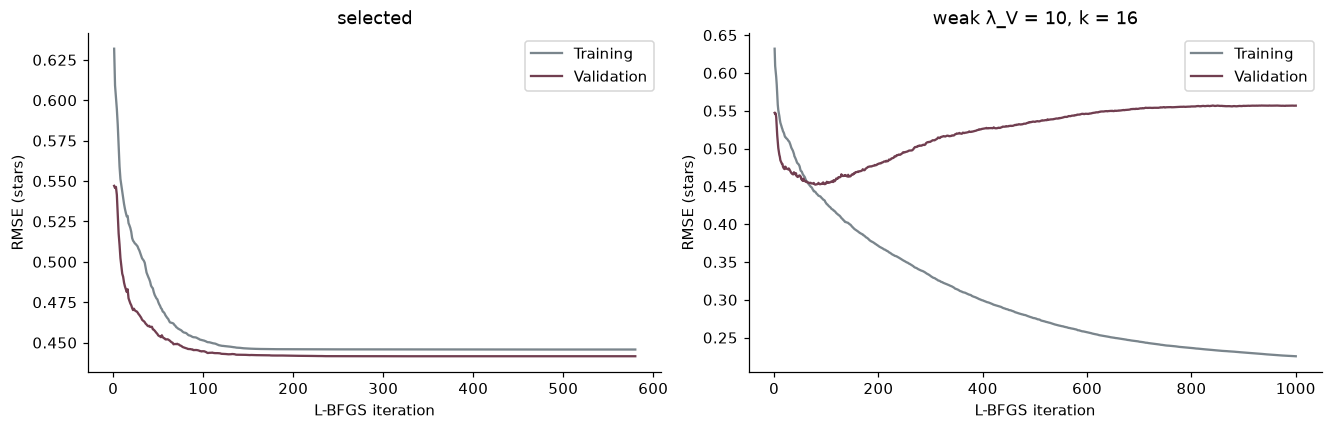

*Source: fm_learning_curves.csv; chronological training and validation events.*

In [11]:
curve = report('fm_learning_curves.csv')
configs = curve['config'].unique()
fig, axes = plt.subplots(1, len(configs), figsize=(6*len(configs), 3.8), squeeze=False,
                         layout='constrained')
for axis, name in zip(axes.flat, configs):
    rows = curve[curve.config.eq(name)]
    axis.plot(rows.iteration, rows.train_rmse, label='Training', color=GRAY)
    axis.plot(rows.iteration, rows.val_rmse, label='Validation', color=WINE)
    axis.set(title=str(name), xlabel='L-BFGS iteration', ylabel='RMSE (stars)')
    axis.legend()
finish(fig, 'Source: fm_learning_curves.csv; chronological training and validation events.')

The weakly regularized run illustrates overfitting; the selected run is judged by validation, not by its lower training error. Sparse encodings avoid materializing a dense user–wine matrix. Item CF still uses a dense wine similarity matrix on Slim; extending that implementation to the Full catalogue requires a sparse neighbour index. Reported Slim scaling measurements and Full projections are distinct: Full was not trained in this study.

In [12]:
display(report('cf_scaling.csv').round(4))

,model,ratings,users,fit_seconds
0,bias,30000,9287,0.0190
1,item_cf,30000,9287,1.7362
2,als_mf k=16,30000,9287,10.0253
3,surprise_svd k=16,30000,9287,0.9466
4,bias,60000,10069,0.0355
5,item_cf,60000,10069,1.9295
6,als_mf k=16,60000,10069,10.4399
7,surprise_svd k=16,60000,10069,1.3392
8,bias,120000,10357,0.0806
9,item_cf,120000,10357,2.2141


<a id="evaluation"></a>
## Evaluation protocol and prediction validity

Event IDs, not row order, align predictions and labels. The shared scorer rejects missing/extra/duplicate IDs and non-finite scores, applies clipping, and reports RMSE/MAE. Published input and split hashes are immutable references; a rerun cannot silently redefine the benchmark.

The primary uncertainty analysis resamples users in a paired bootstrap, keeping both models' predictions aligned. These intervals condition on the fitted models and fixed split. Shared wines, retraining variation and time shifts are not fully captured. For the disjoint-wine experiment, user-bootstrap intervals do not measure uncertainty over newly sampled wines. Existing inspected test results remain exploratory if they influence further model choices.

In [13]:
show_code('score')

[src/pipeline.py — score_predictions](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/src/pipeline.py#L69)

def score_predictions(reference, predictions):
    """Align by RatingID, require full coverage, then apply the shared clipping rule."""
    for frame, required in [(reference, ['RatingID', 'Rating']),
                            (predictions, ['RatingID', 'prediction'])]:
        if not set(required).issubset(frame.columns):
            raise ValueError(f'Required columns: {required}')
        if frame.RatingID.isna().any() or not frame.RatingID.is_unique:
            raise ValueError('RatingID must be non-null and unique')
    if set(reference.RatingID) != set(predictions.RatingID):
        raise ValueError('Prediction IDs must exactly match the evaluation partition')
    aligned = reference[['RatingID', 'Rating']].merge(
        predictions[['RatingID', 'prediction']], on='RatingID', validate='one_to_one')
    values = aligned.prediction.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Predictions must be finite; missing scores cannot be dropped')
    return dict(rows=len(aligned), clipped=int(((values < 1) | (values > 5)).sum()),
                **metrics(aligned.Rating, np.clip(values, 1, 5)))

### Chronological rating prediction

The combined table below uses the original shared references, the collaborative-filtering results and the new linear/FM results. Each row identifies its source. It does not replace earlier reports. Minor numerical differences in reference refits across notebooks are retained in their original files; they do not change the four-decimal conclusions. Timing entries from separate runs are not a controlled cross-machine speed benchmark.

,model,inputs,rmse,mae,source
0,Linear: matched FM features,IDs + attributes + context,0.431515,0.316535,fm_test_metrics.csv
1,FM: attributes + context,IDs + attributes + context,0.431534,0.317374,fm_test_metrics.csv
2,Ridge: attributes + context,IDs + attributes + context,0.433180,0.317727,chronological_test_metrics.csv
3,Item CF,Training rating histories,0.444646,0.334163,cf_test_metrics.csv
4,Surprise SVD,Training rating histories,0.445665,0.334994,cf_test_metrics.csv
5,SVD++,Training rating histories,0.445703,0.335057,cf_test_metrics.csv
6,Regularized bias,Training rating histories,0.445738,0.335551,cf_test_metrics.csv
7,ALS MF,Training rating histories,0.446001,0.335792,cf_test_metrics.csv
8,FM: IDs,IDs,0.446891,0.337005,fm_test_metrics.csv
9,Ridge: IDs,IDs / reference,0.449256,0.340107,chronological_test_metrics.csv


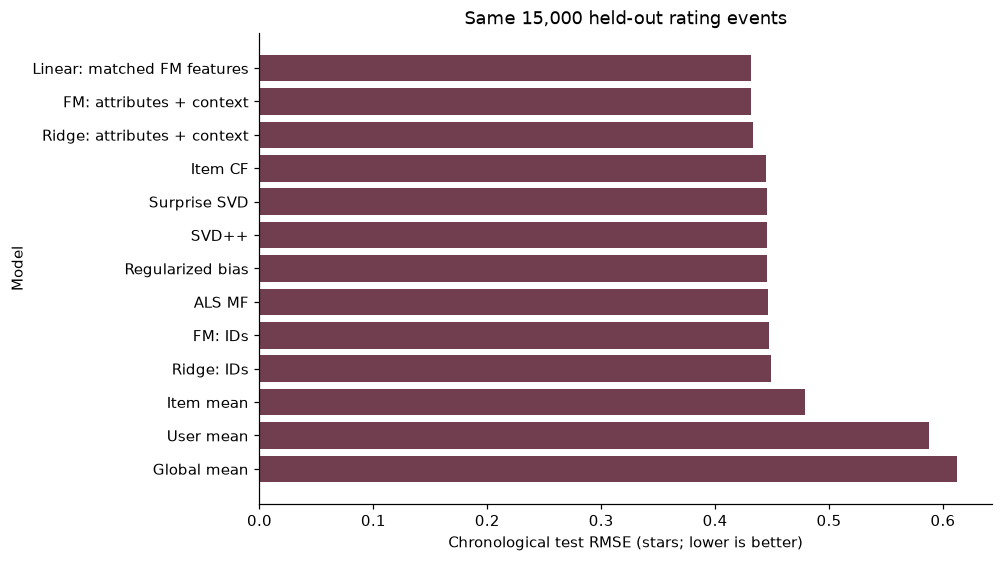

*Sources: chronological_test_metrics.csv, cf_test_metrics.csv, fm_test_metrics.csv.*

In [14]:
base = report('chronological_test_metrics.csv')
cf = report('cf_test_metrics.csv')
fm = report('fm_test_metrics.csv')
records = []
def add(frame, key, label, inputs, source):
    row = frame[frame.model.eq(key)].iloc[0]
    records.append(dict(model=label, inputs=inputs, rmse=row.rmse, mae=row.mae,
                        source=source))
for key, label in [('global','Global mean'), ('user_mean','User mean'),
                   ('item_mean','Item mean'), ('ids','Ridge: IDs'),
                   ('selected_metadata','Ridge: attributes + context')]:
    add(base, key, label, 'IDs / reference' if key!='selected_metadata' else 'IDs + attributes + context',
        'chronological_test_metrics.csv')
for key, label in [('bias','Regularized bias'), ('item_cf','Item CF'), ('als_mf','ALS MF'),
                   ('surprise_svd','Surprise SVD'), ('surprise_svdpp','SVD++')]:
    add(cf, key, label, 'Training rating histories', 'cf_test_metrics.csv')
for key, label in [('linear same features','Linear: matched FM features'),
                   ('fm','FM: attributes + context'), ('fm ids only','FM: IDs')]:
    add(fm, key, label, 'IDs' if key=='fm ids only' else 'IDs + attributes + context', 'fm_test_metrics.csv')
comparison = pd.DataFrame(records).sort_values('rmse').reset_index(drop=True)
display(comparison.round(6))
fig, axis = plt.subplots(figsize=(9, 5), layout='constrained')
axis.barh(comparison.model, comparison.rmse, color=WINE)
axis.invert_yaxis()
axis.set(xlabel='Chronological test RMSE (stars; lower is better)', ylabel='Model',
         title='Same 15,000 held-out rating events')
finish(fig, 'Sources: chronological_test_metrics.csv, cf_test_metrics.csv, fm_test_metrics.csv.')

Context-aware linear and FM predictions have nearly identical point estimates, around 0.4315 RMSE. Item CF makes a small improvement over the bias model, while the tested MF configurations do not show a clear gain over that reference. These results do not establish that personalized preferences are absent, that MF is generally ineffective, or that the linear/FM errors are statistically equivalent.

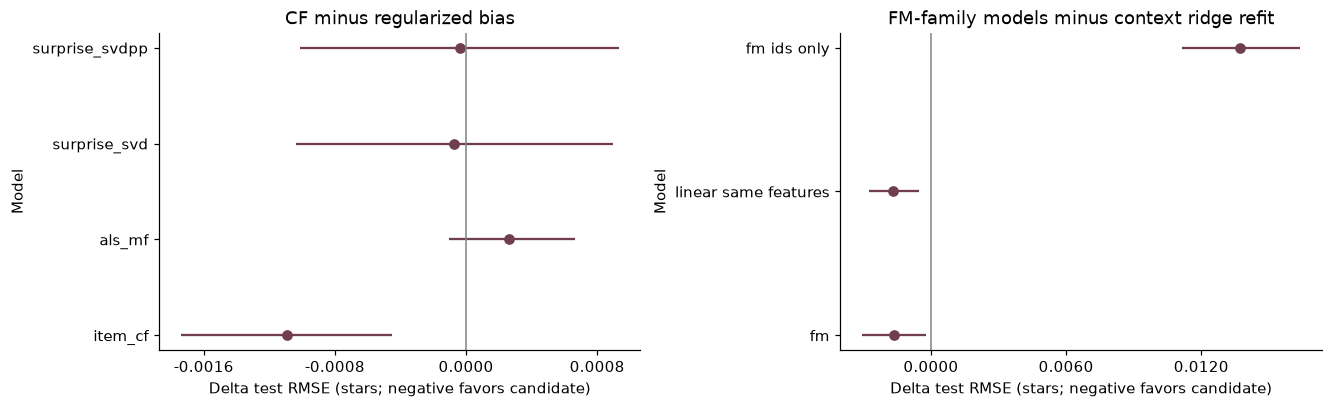

*Paired 95% user-bootstrap intervals from each source report; references differ by panel.*

In [15]:
cf_intervals = cf[cf.vs_bias_ci_low.notna() & ~cf.model.eq('bias')]
fm_intervals = fm[fm.vs_ridge_ci_low.notna()]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout='constrained')
for axis, frame, delta, low, high, title in [
    (axes[0], cf_intervals, 'vs_bias_delta_rmse', 'vs_bias_ci_low', 'vs_bias_ci_high',
     'CF minus regularized bias'),
    (axes[1], fm_intervals, 'vs_ridge_delta', 'vs_ridge_ci_low', 'vs_ridge_ci_high',
     'FM-family models minus context ridge refit')]:
    y = np.arange(len(frame))
    axis.hlines(y, frame[low], frame[high], color=WINE)
    axis.scatter(frame[delta], y, color=WINE)
    axis.axvline(0, color=GRAY, linewidth=1)
    axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
    axis.xaxis.set_major_formatter(FormatStrFormatter('%.4f'))
    axis.set(yticks=y, yticklabels=frame.model, xlabel='Delta test RMSE (stars; negative favors candidate)',
             ylabel='Model', title=title)
finish(fig, 'Paired 95% user-bootstrap intervals from each source report; references differ by panel.')

### Static attributes, calendar time and vintage age

The original ridge context probe combined time and age. The merged FM study adds separate calendar-only and age-only ablations. Compare these **validation** results, rather than attributing a combined test improvement to metadata. Calendar time produces the larger reduction; vintage age contributes a smaller change. The combined change is not an additive causal decomposition, and the FM/linear entries may have different selected settings.

,name,fm,linear,fm_minus_linear,features,step_change_fm
0,ids,0.451341,0.451341,-0.000000,11357,NaN
1,+type,0.451192,0.451192,-0.000000,11363,-0.000150
2,+country,0.451254,0.451254,0.000000,11394,0.000062
3,+grape,0.451392,0.451391,0.000001,11581,0.000138
4,+region,0.450986,0.450985,0.000001,11902,-0.000406
5,all,0.450646,0.450646,-0.000000,12704,-0.000340
6,+time,0.441580,0.441916,-0.000336,12709,-0.009065


,name,fm,linear,fm_minus_linear,features,vs_same_without_context_fm
0,ids,0.451341,0.451341,-0.000000,11357,0.000000
1,ids+Time,0.443190,0.443190,0.000000,11360,-0.008151
2,ids+Age,0.450591,0.450590,0.000001,11359,-0.000750
3,ids+Time+Age,0.442309,0.442274,0.000035,11362,-0.009032
4,all,0.450646,0.450646,-0.000000,12704,0.000000
5,all+Time,0.441725,0.442748,-0.001023,12707,-0.008920
6,all+Age,0.449818,0.449947,-0.000129,12706,-0.000828
7,all+Time+Age,0.441580,0.441916,-0.000336,12709,-0.009065


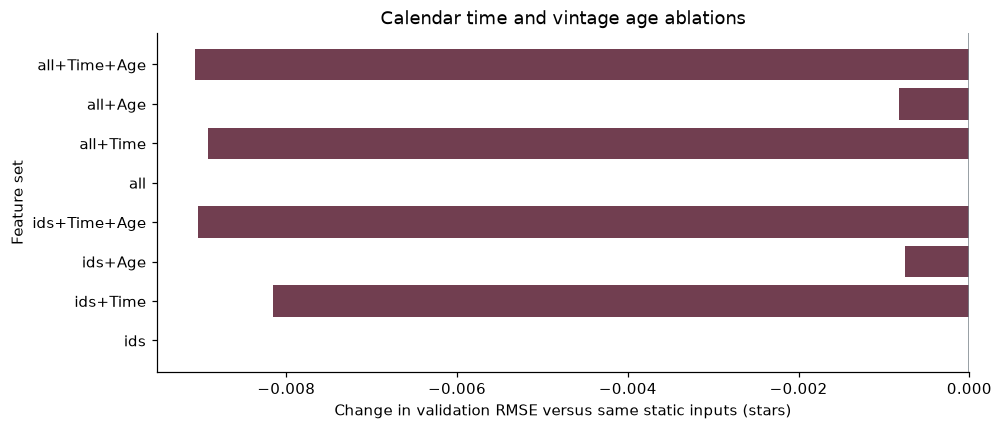

*Source: fm_time_vs_age.csv; validation only. Time is calendar context, Age uses rated vintage.*

In [16]:
display(report('fm_ablation.csv').round(6))
context = report('fm_time_vs_age.csv')
display(context.round(6))
fig, axis = plt.subplots(figsize=(9, 3.8), layout='constrained')
axis.barh(context.name, context.vs_same_without_context_fm, color=WINE)
axis.axvline(0, color=GRAY, linewidth=1)
axis.set(xlabel='Change in validation RMSE versus same static inputs (stars)', ylabel='Feature set',
         title='Calendar time and vintage age ablations')
finish(fig, 'Source: fm_time_vs_age.csv; validation only. Time is calendar context, Age uses rated vintage.')

### Unseen wines and activity groups

The chronological test contains only 16 events for wines without training history, so it is insufficient for a strong cold-item conclusion. The separate disjoint-wine test contains 14,536 events across 101 held-out wines. Its FM wins on validation but underperforms its ridge reference on test. We keep that failure, without using test to reselect a winner. Metadata is useful for scoring an unseen item, but larger interaction models do not automatically generalize to new wines.

In [17]:
display(report('fm_cold_item_test.csv').round(6))
slices = report('fm_error_slices.csv')
display(slices[slices.model.eq('fm') & slices['slice'].isin(['regime','UserID_history'])].round(5))

,model,rmse,mae,fit_seconds,vs_ridge_delta_rmse,vs_ridge_ci_low,vs_ridge_ci_high
0,global,0.688437,0.545141,NaN,0.113988,0.108580,0.119401
1,user_mean,0.639677,0.498164,NaN,0.065228,0.060925,0.069939
2,item_mean,0.688437,0.545141,NaN,0.113988,0.108580,0.119401
3,fm: all+time (main),0.590900,0.463780,35.311068,0.016451,0.013695,0.019151
4,linear: main+extras,0.578782,0.451624,3.631714,0.004333,0.003564,0.005076
5,ridge ids+metadata+time (repo),0.574449,0.449005,NaN,NaN,NaN,NaN


,model,slice,group,n,users,rmse,mae
0,fm,regime,new_both,2,2,0.39166,0.30184
1,fm,regime,new_item,14,14,0.75792,0.53494
2,fm,regime,new_user,981,171,0.50720,0.36438
3,fm,regime,warm_both,14003,5614,0.42528,0.31387
4,fm,UserID_history,0,983,173,0.50699,0.36426
5,fm,UserID_history,1-5,3487,960,0.43842,0.32425
6,fm,UserID_history,6-20,8898,4063,0.42675,0.31472
7,fm,UserID_history,21-100,1632,592,0.39134,0.28890


### Parameter interpretation

Coefficients describe conditional associations in a regularized, correlated feature representation. They are not causal effects or intrinsic wine quality. User/wine identity can absorb much of an attribute's signal; scale matters when reading numeric coefficients.

In [18]:
weights = report('fm_feature_weights.csv')
display(weights[weights.field.isin(['Type','Time','Age','ABV'])]
        [['feature','weight','factor_norm','train_wines']].round(5))
display(report('cf_taste_reliability.csv').round(5))

,feature,weight,factor_norm,train_wines
0,Type=Red,-0.02554,0.02050,506.0
1,Type=Dessert,0.07126,0.01474,58.0
2,Type=Sparkling,0.07694,0.02395,98.0
3,Type=White,-0.08648,0.02367,230.0
4,Type=Dessert/Port,0.17237,0.02201,25.0
5,Type=Rosé,-0.21485,0.03500,83.0
558,ABV_z,0.06010,0.12375,NaN
559,ABV_missing,0.00000,0.00000,NaN
560,month_sin,-0.01216,0.06256,NaN
561,month_cos,0.00500,0.10550,NaN


,Unnamed: 0,value
0,eligible_users,1536.00000
1,split_half_r_mean,0.02961
2,split_half_r_min,-0.01949
3,split_half_r_max,0.07956


### Ranking and recommendation diversity

Ranking is secondary to predicting observed ratings. The saved experiment uses 4,684 training-seen users with at least one eligible held-out rating of at least four stars, a 1,007-wine catalogue, and excludes each user's training wines. Unobserved wines are unlabeled; treating them as non-relevant introduces exposure/selection bias. Catalogue availability at each historical query time is unknown.

The ranked FM uses **static features**, because a never-rated candidate has no known rated vintage. It is not the context-aware model from the main rating table. Popularity has higher reported Recall@10 here; this does not mean it best predicts rating values or necessarily wins in an online experiment.

In [19]:
ranking = report('fm_topk.csv')
diversity = report('fm_diversity.csv')
display(ranking.round(5))
display(diversity[['model','catalogue_coverage','gini','types_per_list','red_share']].round(5))

,model,users,precision_at_k,recall_at_k,mrr,auc
0,fm (IDs + static metadata),4684,0.00790,0.03453,0.02711,0.71377
1,als mf,4684,0.00824,0.03638,0.04066,0.71299
2,bias model,4684,0.00803,0.03488,0.04080,0.71264
3,popularity,4684,0.01830,0.09131,0.07037,0.84945


,model,catalogue_coverage,gini,types_per_list,red_share
0,fm (IDs + static metadata),0.01589,0.98997,3.97822,0.70218
1,als mf,0.02085,0.98970,3.97801,0.70218
2,bias model,0.01589,0.98997,3.97822,0.70218
3,popularity,0.01787,0.98922,1.19748,0.98025
4,catalogue (all wines),NaN,NaN,NaN,0.50248
5,training ratings,NaN,NaN,NaN,0.66438


<a id="conclusions"></a>
## Conclusions and limitations

- Strong additive references explain much of the predictable signal. Item CF adds a small gain; the tested latent-factor models do not clearly outperform the bias model.
- Rating context accounts for more validation improvement than static attributes on warm wines. The calendar/age ablation identifies calendar time as the larger component in this experiment.
- The matched linear model and FM have nearly equal test RMSE. Small gains over the original ridge can reflect regularization and search effort, not just interactions.
- Unseen-item prediction and ranking remain harder questions. The cold-item FM fails to retain its validation advantage, and the ranking objective rewards a different behaviour from predicting rating values.
- Conclusions are limited to the sampled catalogue, observed rating events, fixed partitions and tested searches. Retrospective metadata, user/item dependence, rating selection and missing historical availability limit causal and deployment claims.

This evidence connects the literature to the experiments: item similarity remains a useful small correction; factorized interactions are flexible but need not outperform a well-tuned linear reference; temporal drift deserves explicit modeling. The next experiment should preserve an untouched holdout and focus on the intended recommendation setting before increasing model complexity.

<a id="reproduction"></a>
## Data provenance and reproducibility

Experiment inputs and source excerpts are pinned to the revision below and verified by checksum. Figures and tables are generated from those recorded results. Training configuration, dependency installation and execution commands are documented in the repository README. Numerical results and runtimes can vary with native libraries and hardware.

In [20]:
print('Repository:', 'https://github.com/AviGon/Wine_Recommendation_System')
print('Experiment revision:', SNAPSHOT['source_commit'])
for source in SNAPSHOT['training_sources']:
    display(Markdown('['+source['label']+' source](https://github.com/AviGon/Wine_Recommendation_System/blob/'
                     + SNAPSHOT['source_commit'] + '/' + source['path'] + ')'))

Repository: https://github.com/AviGon/Wine_Recommendation_System
Experiment revision: 9bba3f248dc08c114ce9a8d0c066b5f1249101d4


[Rating analysis source](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/scripts/build_notebook.py)

[Collaborative filtering source](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/scripts/build_cf_notebook.py)

[Factorization machines source](https://github.com/AviGon/Wine_Recommendation_System/blob/9bba3f248dc08c114ce9a8d0c066b5f1249101d4/scripts/build_fm_notebook.py)